# Experiment 2 — LLM-Generated Explanation Faithfulness for Hospital Readmission Prediction

## 1. Research objective and hypotheses

This experiment asks how faithfully local Qwen3 describes a fitted model’s 30-day readmission prediction.

- **H1 · SHAP grounding.** Supplying case-level attributions improves agreement with the fitted model’s most influential features and their directions.
- **H2 · Deterministic verification.** Checking the grounded draft, requesting a correction, and using a fallback when needed improves the final system’s agreement and completeness.

Signed top-three agreement is the primary structured measure. Narrative checks measure agreement within the verifier’s grammar and document how much prose the grammar covers.

## 2. Experimental design and dataset

The pinned Experiment 1 XGBoost model and cohort supply the predictions and SHAP references. The held-out sample contains 72 distinct patients, with 24 cases drawn from each of the low, middle, and high predicted-risk tertiles. The saved case order is used for all conditions. The notebook keeps feature payloads, original prose, and case-level scores private.

SHAP decomposes the raw log-odds margin relative to a 64-admission training reference. Absolute magnitude determines rank, and the sign describes the contribution relative to that reference. The displayed prediction is the classifier probability. Interpret attribution as model behavior and avoid causal or treatment conclusions.

## 3. Local Qwen3 environment and reproducibility

Select the HRP Python environment installed with `uv sync --locked`. The saved run used `qwen3:8b` through numeric-loopback Ollama, temperature 0, seed 42, a 4,096-token context, a 512-token generation cap, and a 90-second request timeout. Generation used JSON mode with thinking and streaming disabled. The checkpoint records the digest, case fingerprints, pinned provenance, and prompt, verifier, and scorer versions.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

source = next(path for path in (Path("src"), Path("."), Path("HRP/src"))
              if (path / "experiment2_analysis.py").is_file())
sys.path.insert(0, str(source.resolve()))

from experiment2_analysis import (
    ANALYSIS_VERSION, BOOTSTRAP_REPLICATES, BOOTSTRAP_SEED, REVIEW_SEED,
    analyze, notebook_run, save_analysis,
)
from experiment2_figures import build_figures
from experiment2_smoke import fictional_cases
from llm_verification import RESPONSE_SCHEMA, build_prompt

/Users/sghosh/Documents/Github/AI380H/HRP/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 4. Explanation conditions A, B, and C

| Condition | Inputs and release criteria |
|---|---|
| **A · Baseline** | Observed feature values, units, and predicted probability. Qwen3 may abstain. |
| **B · SHAP-grounded** | Same inputs plus the signed, ranked SHAP reference. Retain Qwen3’s original response. |
| **C · SHAP-verified** | Check the exact B draft, attempt at most one Qwen3 revision, and render a deterministic explanation if the revision fails. |

A and B are independent Qwen3 generations for the same case. C is the output of a verification system that may include a model revision or deterministic text.

## 5. Prompt templates and response schema

The shared JSON schema contains one explanation of at most 90 words and up to three feature–direction records. Two or three sentences are requested. The parser rejects malformed JSON, duplicate keys, unknown features, invalid directions, and excess words. Prompts omit observed outcomes and identifiers. The optional examples use fictional inputs.

In [2]:
SHOW_FICTIONAL_PROMPTS = False
display(RESPONSE_SCHEMA)
if SHOW_FICTIONAL_PROMPTS:
    example = fictional_cases()[0]
    for condition in ("A", "B"):
        print(build_prompt(example, condition))

{'explanation': 'Nonempty string, at most 90 words. Aim for 2–3 sentences.',
 'drivers': [{'feature': 'supplied feature key',
   'direction': 'positive or negative'}]}

## 6. Verification methodology

The structured check compares feature membership, sign, and relative order against the non-negligible reference top three. A contribution with absolute value at most `1e-8` log-odds is negligible. Saved rank breaks exact ties. Correct subsets and abstentions remain valid for A and B.

C also requires an explicit, verified prose direction for every reference top driver. The rule-based parser checks recognized claims and records ambiguous wording. An omitted or unparsed directional claim can trigger revision even if all JSON drivers are correct. C releases a complete draft, an accepted revision, or a deterministic rendering of the reference drivers.

## 7. Fictional validation and unit-test evidence

The scripted smoke test uses eight fabricated cases with additive local attribution references. It checks all three conditions, a malformed response, a revision timeout, fallback, and checkpoint resume. The completed smoke produced 24 condition records from 21 scripted calls, with no calls on completed resume. Use fictional mode to repeat it.

Run the offline suite from HRP with `uv run --locked python -m unittest discover -s tests`. The suite uses fictional fixtures for generation, scoring, and checkpoint analysis.

## 8. Real-data benchmark configuration

| Mode | Behavior |
|---|---|
| `review` | Read and validate the completed checkpoint and pinned references. No Ollama requests. |
| `fictional` | Repeat the scripted eight-case validation. |
| `real` | Start or resume the pinned benchmark in an explicitly supplied dedicated private directory outside Git. |

The completed original benchmark remains at the legacy MIMIC-IV root checkpoint. Leave a new run directory unset to prevent accidental generation. Analysis export is optional and always uses a new directory.

In [3]:
MODE = "review"
MIMIC_ROOT = Path.home() / "Library/Application Support/AI380H/MIMIC-IV"
REVIEW_CHECKPOINT = MIMIC_ROOT / "checkpoint.json"
REAL_RUN_DIRECTORY = None  # Example: MIMIC_ROOT / "llm-runs/experiment2-qwen3-replication"
REAL_RUNTIME_SECONDS = 4 * 60 * 60
ANALYSIS_EXPORT_DIRECTORY = MIMIC_ROOT / "llm-runs/experiment2-qwen3-replication-analysis"  # An unused owner-only directory outside Git.

## 9. Load or execute the 72-case experiment

Review checks the checkpoint against the pinned bundle and case fingerprints. It validates condition coverage, inference accounting, and C’s exact reuse of B. A completed run selected in real mode is also loaded without generation. If a new real run pauses, use the same dedicated directory to resume it.

In [4]:
run = notebook_run(
    MODE, checkpoint=REVIEW_CHECKPOINT, run_directory=REAL_RUN_DIRECTORY,
    runtime_seconds=REAL_RUNTIME_SECONDS,
)
analysis = None
figures = {}
reference_run = False
if MODE == "fictional":
    display(run["fictional"])
else:
    state, score = run["state"], run["score"]
    manifest = state["manifest"]
    original_sha256 = "42038ff9ceef439a3bb8797b419869ed7638610173c36e18f4a9631f122a047a"
    reference_run = run["checkpoint_sha256"] == original_sha256
    complete = not score["operations"]["statuses"].get("pending", 0)
    display({
        "complete": complete, "pause_reason": state["pause_reason"],
        "cases": len(manifest["cases"]), "model": manifest["provenance"]["model_id"],
        "cohort": manifest["provenance"]["cohort_id"], "checkpoint_sha256": run["checkpoint_sha256"],
        "versions": {name: manifest[f"{name}_version"] for name in ("prompt", "verifier", "scorer")},
        "generation": manifest["configuration"],
    })
    if complete:
        analysis = analyze(run)
        figures = build_figures(analysis)
        for figure in figures.values():
            plt.close(figure)

{'complete': True,
 'pause_reason': None,
 'cases': 72,
 'model': 'models-20261122T230904Z-511d7f06',
 'cohort': 'run-20261122T212339Z-c71630d2',
 'checkpoint_sha256': '42038ff9ceef439a3bb8797b419869ed7638610173c36e18f4a9631f122a047a',
 'versions': {'prompt': 'experiment2-v3',
  'verifier': 'experiment2-verifier-v3',
  'scorer': 'experiment2-scorer-v1'},
 'generation': {'inference': 'ollama',
  'model': {'model': 'qwen3:8b',
   'endpoint': 'http://127.0.0.1:11434',
   'digest': '500a1f067a9f782620b40bee6f7b0c89e17ae61f686b92c24933e4ca4b2b8b41',
   'temperature': 0,
   'seed': 42,
   'num_ctx': 4096,
   'num_predict': 512},
  'request_timeout': 90,
  'generation': {'format': 'json', 'stream': False, 'think': False}}}

## 10. Execution completeness and inference costs

The completed benchmark contains 216 condition records and 214 valid final outputs. The two invalid finals were baseline responses. Seven revision schema failures are included in the request-level failure count, and there were no recorded inference failures.

Latency is summed request time. End-to-end wall time and verifier CPU time were not instrumented. C uses B’s initial call, so full C delivery includes B generation plus any revision. The total counts each request once.

{'records': 216,
 'statuses': {'ok': 214, 'parse_error': 2},
 'parse_failures': 9,
 'inference_failures': {},
 'calls': 216,
 'latency_seconds': 2524.6465354620304,
 'intervention_counts': {'draft_accepted': 0,
  'revision_requested': 72,
  'revision_accepted': 8,
  'revision_rejected': 64,
  'fallback_used': 64}}

,stage,calls,seconds,mean_seconds,median_seconds
0,A,72,802.75,11.15,9.75
1,B,72,1132.57,15.73,15.53
2,C,72,589.33,8.19,7.90
3,C delivery (B + C),144,1721.90,11.96,13.06
4,Total unique,216,2524.65,11.69,9.86


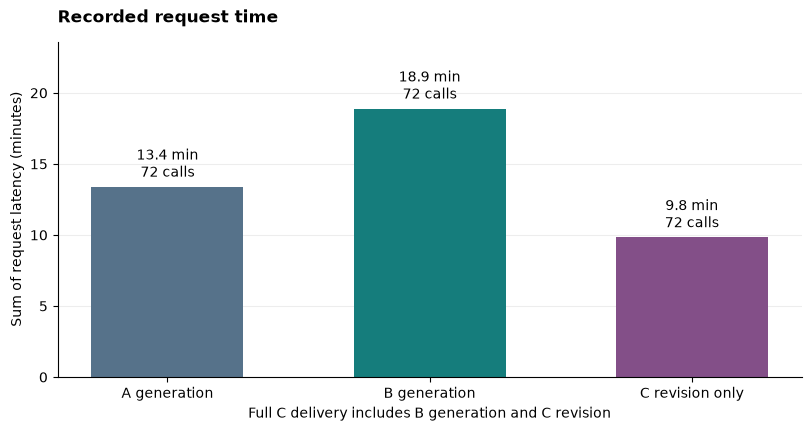

In [5]:
if analysis:
    display(analysis["operations"])
    display(pd.DataFrame(analysis["costs"]).round(2))
    display(figures["experiment2_request_cost"])

## 11. Structured attribution-faithfulness results

Overlap, signed agreement, and rank-position agreement range from 0 to 3. Exact order uses feature keys, while signed agreement also requires the correct direction. Structured correctness permits a correct subset; completeness tests whether every reference driver is present. Means and percentages in this section use valid outputs. The paired section includes a failure-inclusive sensitivity analysis.

,condition,valid,total,top_three_overlap,signed_top_three_agreement,rank_position_agreement,exact_top_three_ordering,missing_influential_drivers,incorrect_feature_directions,structured_correct,structured_complete
0,A,70,72,1.343,1.000,0.386,1.4%,1.657,0.714,7.1%,4.3%
1,B,72,72,2.944,2.917,2.722,87.5%,0.056,0.028,86.1%,95.8%
2,C,72,72,3.000,3.000,3.000,100.0%,0.000,0.000,100.0%,100.0%


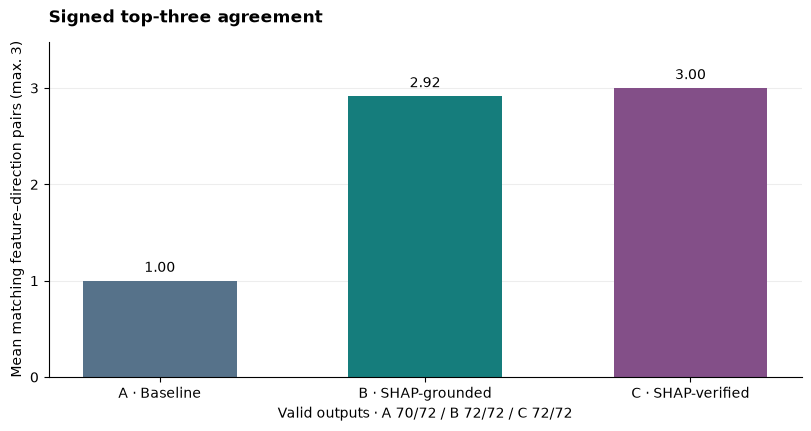

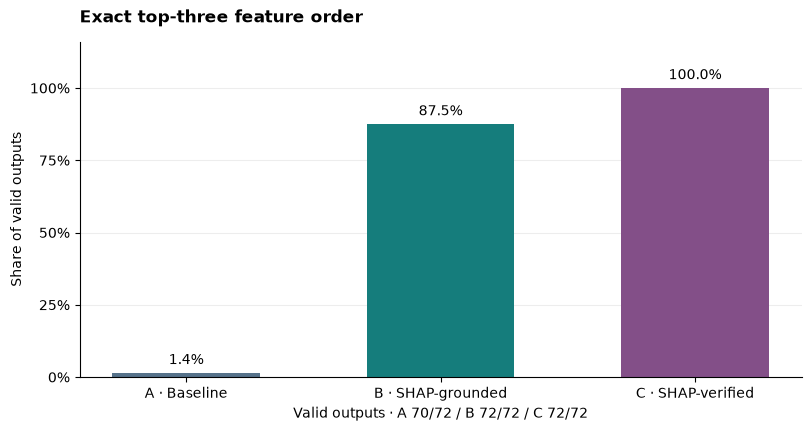

In [6]:
if analysis:
    structured = pd.DataFrame(analysis["structured"])
    for column in ("exact_top_three_ordering", "structured_correct", "structured_complete"):
        structured[column] = structured[column].map(lambda value: f"{value:.1%}")
    display(structured.round(3))
    display(figures["experiment2_signed_agreement"])
    display(figures["experiment2_exact_ranking"])

## 12. Narrative faithfulness and verifier coverage

Coverage is the number of automatically checked clauses divided by checked plus unparsed or ambiguous clauses. Purely descriptive clauses are excluded. Missing directions count reference drivers for which the verifier found no supported directional statement. This includes genuinely omitted directions and directions the grammar could not recognize. Prose completeness requires coverage of every reference driver within an output.

In the original benchmark, the verifier checked 15 of 194 candidate B clauses and found 13 supported directions. A had one checked clause and no supported directions. These counts describe the parser’s reach. Unparsed clauses do not establish agreement or contradiction. The figure presents coverage by clause and structured and prose measures by output.

,condition,valid,verified_directional_clauses,incorrect_directional_clauses,unsupported_claim_clauses,contradicted_clauses,checked_clauses,unparsed_clauses,descriptive_clauses,missing_top_three_directions,complete_prose_outputs,parser_coverage,prose_completeness
0,A,70,0,0,1,1,1,209,68,210,0,0.5%,0.0%
1,B,72,13,0,2,2,15,179,62,203,0,7.7%,0.0%
2,C,72,216,0,0,0,216,0,72,0,72,100.0%,100.0%


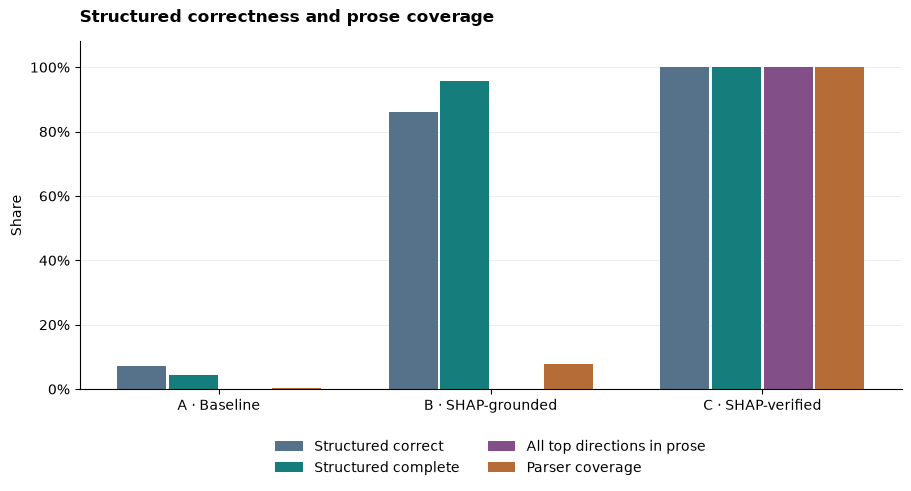

In [7]:
if analysis:
    prose = pd.DataFrame(analysis["narrative"])
    for column in ("parser_coverage", "prose_completeness"):
        prose[column] = prose[column].map(lambda value: f"{value:.1%}")
    display(prose)
    display(figures["experiment2_structure_and_prose"])

## 13. Verification, revision, and fallback analysis

All 72 original B drafts triggered revision. Sixty-two had correct structured drivers and ambiguous prose. Two drafts contained a clause flagged as an unsupported feature claim; the direction and rank rows below include structured findings. Categories count responses and can overlap. The rejected-revision column uses only the 64 rejected revisions as its denominator.

Eight cases improved through an accepted Qwen3 revision. The other 64, or 88.9% of C, reached completeness through deterministic rendering. The final C scores therefore measure the full system.

,outcome,count
0,draft_accepted,0
1,revision_requested,72
2,revision_accepted,8
3,revision_rejected,64
4,fallback_used,64
5,verified_complete,72


{'rejected': 72,
 'structured_correct': 62,
 'structured_correct_and_ambiguous': 62,
 'responses_with_contradictions': 2}

,C source,pairs,left_mean,right_mean,mean_change
0,deterministic_fallback,64,2.906,3,0.094
1,model_revision,8,3.000,3,0.000


,stage,reason,count,denominator,percent
0,original B,Missing explicit directional prose,72,72,100.0
1,original B,Unparsed or ambiguous wording,72,72,100.0
2,original B,Incorrect SHAP direction,1,72,1.4
3,original B,Unsupported clinical interpretation,0,72,0.0
4,original B,Numerical scale error,0,72,0.0
5,original B,Ranking error,6,72,8.3
6,original B,Other,5,72,6.9
7,rejected revision,Missing explicit directional prose,54,64,84.4
8,rejected revision,Unparsed or ambiguous wording,54,64,84.4
9,rejected revision,Incorrect SHAP direction,0,64,0.0


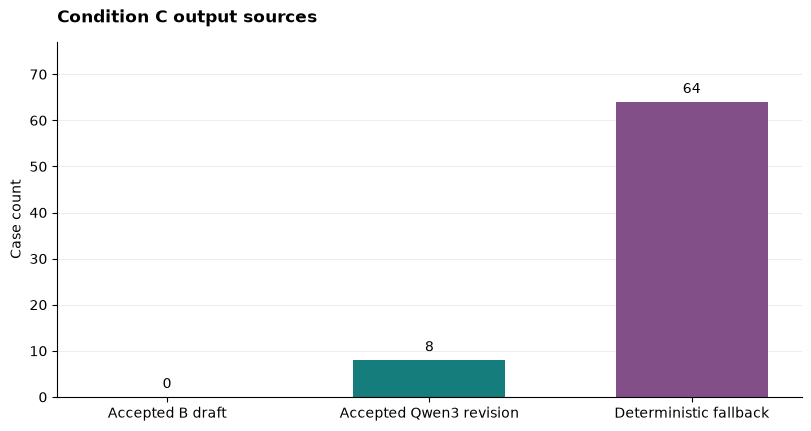

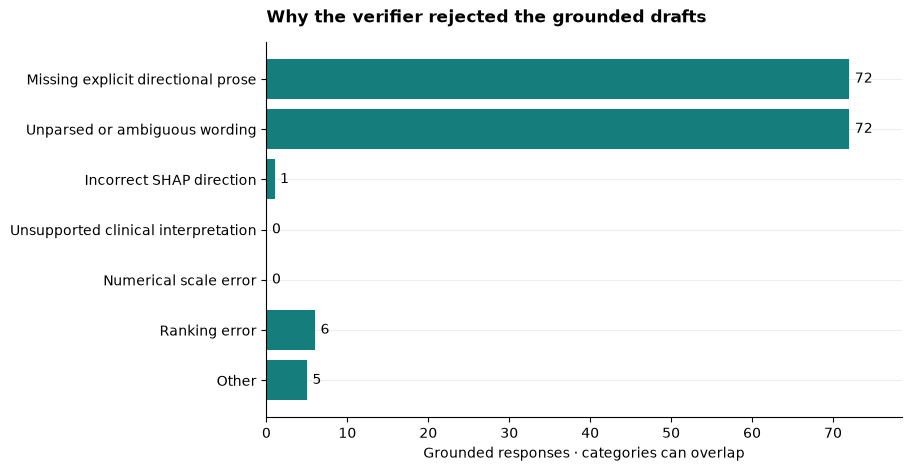

In [8]:
if analysis:
    display(pd.DataFrame(analysis["interventions"]))
    display(analysis["grounded_audit"])
    source_pairs = score["paired"]["B_to_C"]["by_source"]
    display(pd.DataFrame([
        {"C source": source.split(" → ")[1], "pairs": pair["pairs"], **pair["metrics"]["signed_top_three_agreement"]}
        for source, pair in source_pairs.items()
    ]).round(3))
    display(pd.DataFrame(analysis["rejections"]).round(1))
    display(figures["experiment2_intervention_sources"])
    display(figures["experiment2_grounded_rejections"])

## 14. Paired statistical comparisons

The estimand is the mean right-minus-left difference across aligned cases. The 95% percentile intervals use 10,000 bootstrap replicates with seed 380, resampling each case’s paired outputs together. Complete-case estimates exclude pairs with invalid output. The separate sensitivity analysis scores invalid outputs as zero on bounded attribution measures. The intervals describe this deliberately risk-stratified sample and do not estimate clinical deployment performance.

,comparison,metric,pairs,observed_valid_pairs,excluded_pairs,mean_difference,ci95_low,ci95_high
0,A→B,top_three_overlap,70,70,2,1.6000,1.4286,1.7714
1,A→B,signed_top_three_agreement,70,70,2,1.9429,1.7571,2.1286
2,A→B,rank_position_agreement,70,70,2,2.3286,2.1000,2.5429
3,A→B,exact_top_three_ordering,70,70,2,0.8571,0.7714,0.9286
8,B→C,top_three_overlap,72,72,0,0.0556,0.0000,0.1250
9,B→C,signed_top_three_agreement,72,72,0,0.0833,0.0139,0.1806
10,B→C,rank_position_agreement,72,72,0,0.2778,0.1111,0.4722
11,B→C,exact_top_three_ordering,72,72,0,0.1250,0.0556,0.2083
16,A→C,top_three_overlap,70,70,2,1.6571,1.4857,1.8286
17,A→C,signed_top_three_agreement,70,70,2,2.0000,1.8143,2.1857


,comparison,metric,pairs,observed_valid_pairs,excluded_pairs,mean_difference,ci95_low,ci95_high
4,A→B,top_three_overlap,72,70,0,1.6389,1.4583,1.8056
5,A→B,signed_top_three_agreement,72,70,0,1.9444,1.7639,2.1250
6,A→B,rank_position_agreement,72,70,0,2.3472,2.1250,2.5556
7,A→B,exact_top_three_ordering,72,70,0,0.8611,0.7778,0.9306
12,B→C,top_three_overlap,72,72,0,0.0556,0.0000,0.1250
13,B→C,signed_top_three_agreement,72,72,0,0.0833,0.0139,0.1806
14,B→C,rank_position_agreement,72,72,0,0.2778,0.1111,0.4722
15,B→C,exact_top_three_ordering,72,72,0,0.1250,0.0556,0.2083
20,A→C,top_three_overlap,72,70,0,1.6944,1.5139,1.8750
21,A→C,signed_top_three_agreement,72,70,0,2.0278,1.8472,2.2083


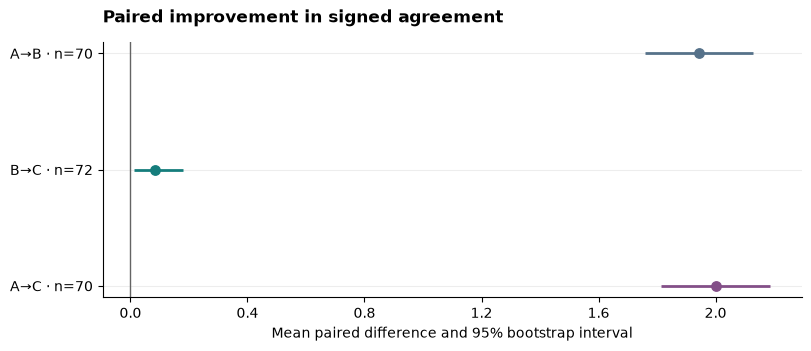

In [9]:
if analysis:
    comparisons = pd.DataFrame(analysis["paired"])
    for method in ("complete_case", "failure_inclusive"):
        display(comparisons[comparisons["analysis"] == method].drop(columns="analysis").round(4))
    display(figures["experiment2_paired_improvement"])

## 15. Representative error analysis

A private exploratory review selected one case per criterion using seed 383. Criteria covered correct and incorrect structured drivers, contradiction, ambiguity, accepted revision, and fallback. Each selection was compared with the saved signs, ranks, and trace. The notes below paraphrase the findings without feature values, case identifiers, or quotations. The six selections are diagnostic and do not estimate a population error rate.

In [10]:
manual_observations = None
if reference_run:
    manual_observations = {
        "correct structured drivers": "The signs and order were correct. A grouped clause did not make clear which listed features shared the stated direction.",
        "incorrect structured drivers": "A feature outside the reference top three replaced an influential feature. The remaining prose also used modifiers the parser did not resolve.",
        "narrative contradiction": "A generic statement about model-influencing features triggered the unsupported-feature rule. The phrase did not name a false feature, and the signed JSON drivers matched.",
        "ambiguous prose": "A list used a shared decreasing predicate. All listed features had negative reference signs, but the verifier did not distribute the predicate across the list.",
        "accepted revision": "The revision gave each feature a directional clause. Its short pronouns had a clear predicted-risk antecedent and all three signs matched.",
        "deterministic fallback": "The revision retained correct drivers but embedded the first direction in a relative clause. The deterministic output provided explicit directions for all three.",
    }
    display(pd.Series(manual_observations, name="Private review finding, paraphrased").to_frame())

,"Private review finding, paraphrased"
correct structured drivers,The signs and order were correct. A grouped cl...
incorrect structured drivers,A feature outside the reference top three repl...
narrative contradiction,A generic statement about model-influencing fe...
ambiguous prose,A list used a shared decreasing predicate. All...
accepted revision,The revision gave each feature a directional c...
deterministic fallback,The revision retained correct drivers but embe...


## 16. Discussion and limitations

**H1.** Grounding raised signed agreement by **1.943 out of 3** across 70 valid pairs (95% CI **1.757–2.129**). Including the two malformed baseline outputs gave **1.944** across 72 cases (95% CI **1.764–2.125**). B also had more recognizable directional statements. Its low parser coverage and the exploratory review limit claims about overall narrative faithfulness.

**H2.** Verification raised signed agreement by **0.083 out of 3** across 72 pairs (95% CI **0.014–0.181**) and produced 72 verified-complete outputs. Eight revisions passed. The 64 fallbacks account for most of C’s delivery, so full system accuracy is distinct from Qwen3’s correction rate.

Free-form grouped predicates, relative clauses, and indirect model-risk phrasing often escaped the parser. The audit found both real structured errors and grounded prose that was compatible with the reference but outside the parser’s grammar. Tighter language can improve checkability at a cost to naturalness and possibly readability. SHAP signs concern the fitted margin relative to a reference, and do not establish causal effects. The evaluation used one Qwen3 variant, one fitted predictor, and one hospital system.

## 17. Experiment 3 handoff

The planned synthetic model-reversal study can test whether explanations follow a changed model relationship when feature values are held fixed. Preserve the prompt, verifier, and scorer lineage for comparison and label any revised grammar as a new analysis. The planned Experiment 5 human review will assess narrative faithfulness and readability systematically, including prose the automatic verifier could not resolve.

Optional export writes aggregate tables and PNG/PDF figures, along with owner-only case scores and audit selections. It records the original checkpoint checksum, analysis version, bootstrap settings, and review method in a new bundle.

In [11]:
if analysis and ANALYSIS_EXPORT_DIRECTORY is not None:
    derived_directory = save_analysis(
        ANALYSIS_EXPORT_DIRECTORY, analysis, run["checkpoint_sha256"],
        run["state"]["manifest"], figures, manual_observations=manual_observations,
    )
    print(f"Analysis bundle written to {derived_directory}")

Analysis bundle written to /Users/sghosh/Library/Application Support/AI380H/MIMIC-IV/llm-runs/experiment2-qwen3-replication-analysis
